<a href="https://colab.research.google.com/github/codebyjuveria/AI-Mini-Projects./blob/main/LogisticsRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

import pandas as pd

import seaborn as sns

import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/framingham.csv")

In [ ]:
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [ ]:
df.tail()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [ ]:
df.isnull().sum()

,0
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Replace the missing values

num_cols = ['cigsPerDay','totChol','BMI','heartRate','glucose']

for col in num_cols:

  df[col] = df[col].fillna(df[col].median())






In [ ]:
# categorical

cat_cols = ['education','BPMeds']

for col in cat_cols:

  df[col] = df[col].fillna(df[col].mode()[0])

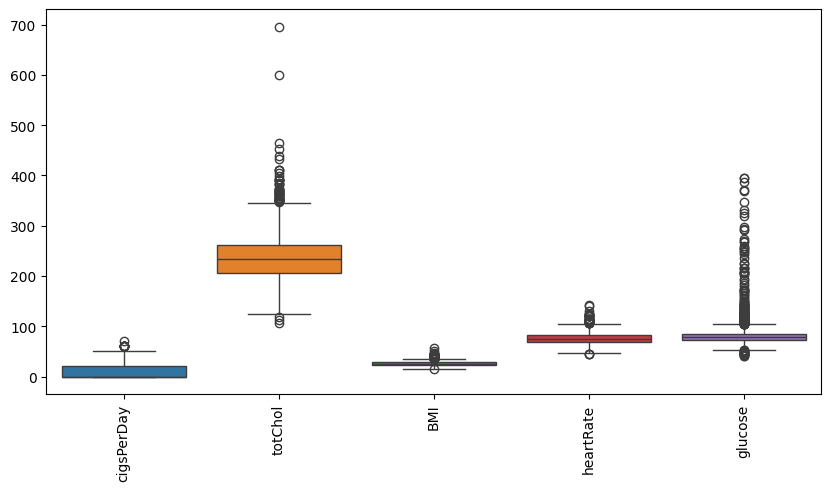

In [ ]:
#outliers

plt.figure(figsize=(10,5))

sns.boxplot(data = df[num_cols])

plt.xticks(rotation=90)

plt.show()

In [ ]:
# Remove Outliers

for col in num_cols:

  q1 = df[col].quantile(0.25)

  q3 = df[col].quantile(0.75)

  iqr = q3 - q1

  lower_bound = q1 - 1.5 * iqr

  upper_bound = q3 + 1.5 * iqr

  df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

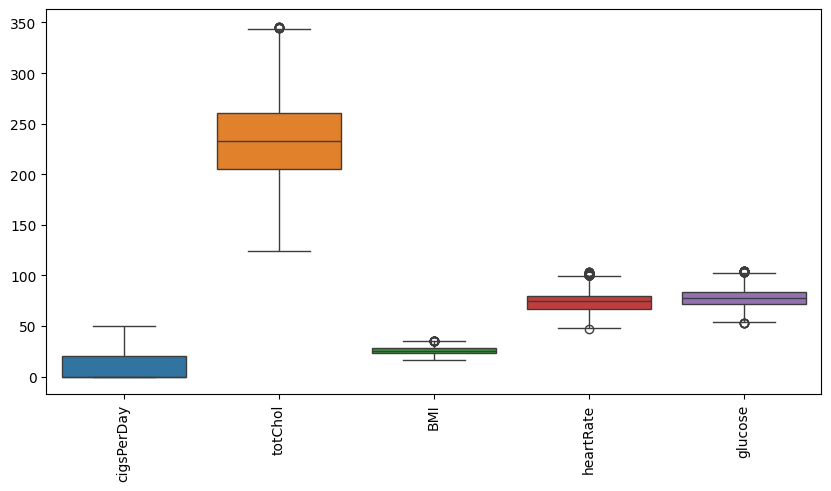

In [ ]:
#outliers

plt.figure(figsize=(10,5))

sns.boxplot(data = df[num_cols])

plt.xticks(rotation=90)

plt.show()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['TenYearCHD'].value_counts(normalize=True)*100

,proportion
TenYearCHD,
0,86.003732
1,13.996268


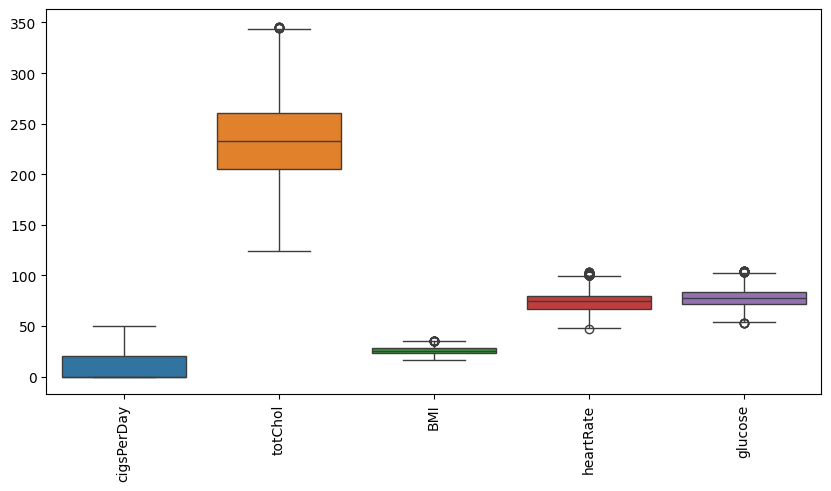

In [ ]:
#outliers

plt.figure(figsize=(10,5))

sns.boxplot(data = df[num_cols])

plt.xticks(rotation=90)

plt.show()

In [ ]:
# Remove Outliers

for col in num_cols:

    q1 = df[col].quantile(0.25)

    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr

    upper_bound = q3 + 1.5 * iqr

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]


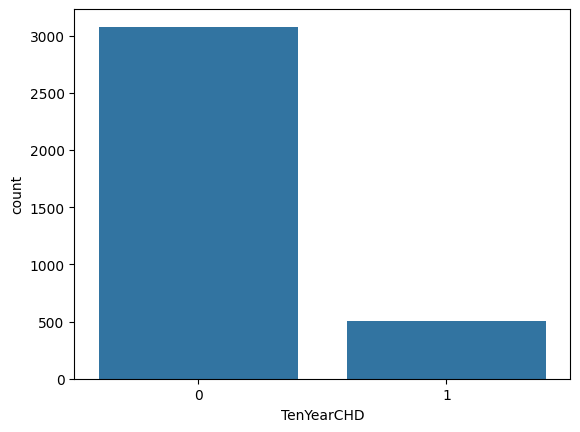

In [ ]:
# Univariate

sns.countplot(x=df['TenYearCHD'])

plt.show()


In [ ]:
df['TenYearCHD'].value_counts()

,count
TenYearCHD,
0,3078
1,504


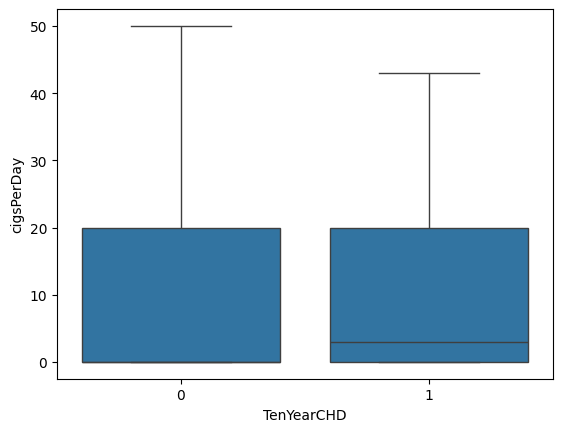

In [ ]:
# Bivariate

sns.boxplot(data = df, x = 'TenYearCHD', y = 'cigsPerDay')

plt.show()


In [ ]:
df.groupby('TenYearCHD')['cigsPerDay'].mean()

,cigsPerDay
TenYearCHD,
0,8.621832
1,10.557540


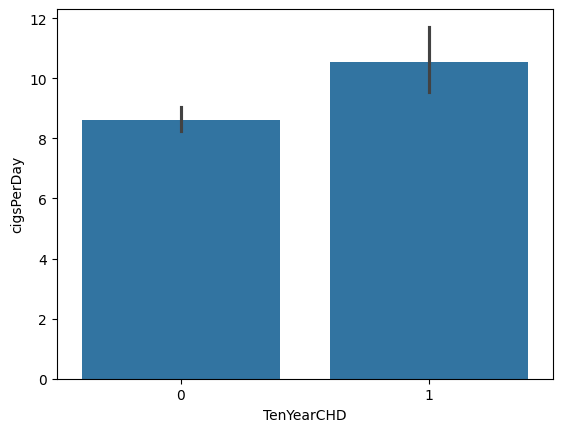

In [ ]:
sns.barplot(data = df, x = 'TenYearCHD', y = 'cigsPerDay')

plt.show()

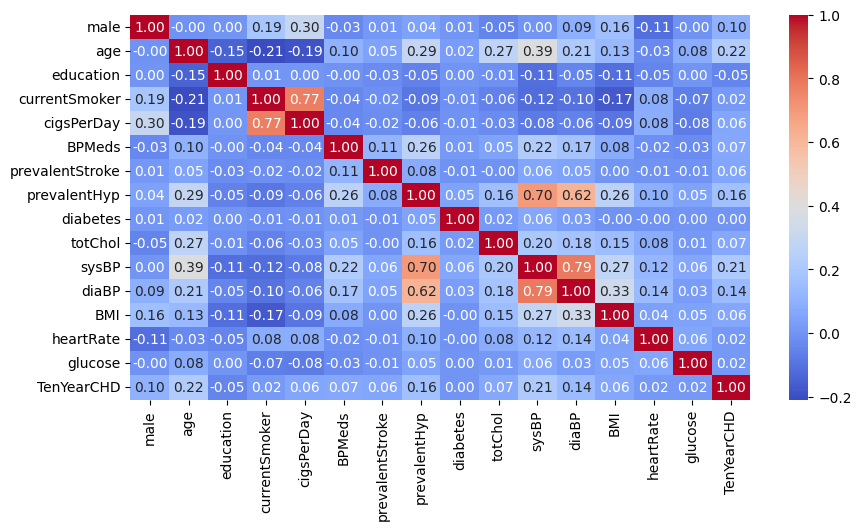

In [ ]:
# Multi variate

plt.figure(figsize=(10,5))

sns.heatmap(df.corr(), annot=True,cmap = 'coolwarm',fmt ='.2f')

plt.show()

In [ ]:
df.corr(numeric_only = True)['TenYearCHD'].sort_values(ascending=True)


,TenYearCHD
education,-0.046021
diabetes,0.003610
heartRate,0.016474
glucose,0.016755
currentSmoker,0.021077
cigsPerDay,0.058252
prevalentStroke,0.058877
BMI,0.060761
BPMeds,0.065444
totChol,0.069295


In [ ]:
df.corr(numeric_only = True)['TenYearCHD'].sort_values(ascending=True)

,TenYearCHD
education,-0.046021
diabetes,0.003610
heartRate,0.016474
glucose,0.016755
currentSmoker,0.021077
cigsPerDay,0.058252
prevalentStroke,0.058877
BMI,0.060761
BPMeds,0.065444
totChol,0.069295


In [ ]:
# Separate X & Y

X = df.drop('TenYearCHD', axis=1)

y = df['TenYearCHD']

print(X.shape)

print(y.shape)


(3582, 15)
(3582,)


In [ ]:
# Import Train_test_split

from sklearn.model_selection import train_test_split



In [ ]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)


In [ ]:
print(X.shape)

print(y.shape)

(3582, 15)
(3582,)


In [ ]:
# Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)






In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = LogisticRegression()

model.fit(X_train, y_train)


LogisticRegression()

In [ ]:
y_pred = model.predict(X_test)






In [ ]:
print(y_pred[:10])






[0 0 0 0 0 0 0 0 0 0]


In [ ]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

results.head(10)






,Actual,Predicted
4137,0,0
1113,0,0
1543,0,0
1253,1,0
2523,0,0
2285,0,0
3441,0,0
3265,0,0
3893,0,0
1147,0,0


[[610   6]
 [ 94   7]]


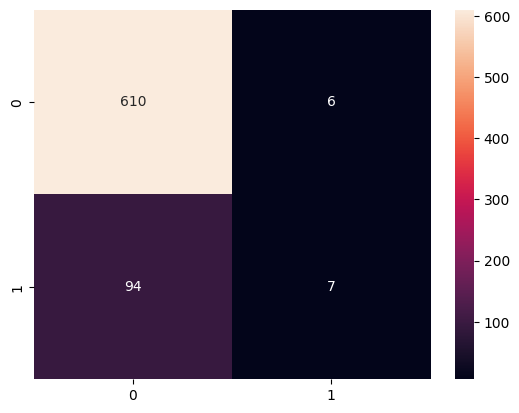

In [ ]:
# Metrics

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

print(cm)

# visualization

sns.heatmap(cm, annot=True, fmt='d')

plt.show()






In [ ]:
# classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.99      0.92       616
           1       0.54      0.07      0.12       101

    accuracy                           0.86       717
   macro avg       0.70      0.53      0.52       717
weighted avg       0.82      0.86      0.81       717



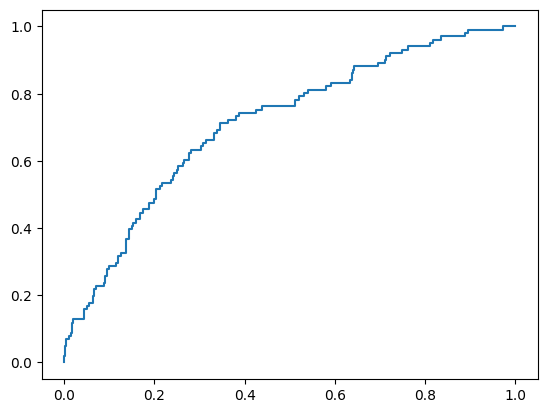

In [ ]:
# ROC-AUC Curve

from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

#Roc curve

plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc_score(y_test, y_prob))

plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob)

print("AUC:", round(auc,3))

AUC: 0.713
